# Model run

In [1]:
# Set scenario name
SCENARIO_NAME = 'temp'
NEW_MT_CENTRES = []

In [2]:
import contextily as ctx
import geopandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classes.geography_processing import Geoprocessing
from classes.model import Model
from classes.scenario import Scenario
from classes.add_net_benefit import add_net_benefit


In [3]:
hospitals = pd.read_csv('data/stroke_hospitals_2025.csv')

# Get postcode for all hospitals with Use_IVT=1 and Use_MT=0
units_to_test = hospitals['Postcode'][
    ((hospitals['Use_IVT'] == 1) &
     (hospitals['Use_MT'] == 0) &
     (hospitals['Country'] == 'England'))].tolist()


In [4]:
# Run base case model to get baseline net benefit
SCENARIO_NAME = 'Base case'
NEW_MT_CENTRES = []
geo = Geoprocessing(mt_travel_bias = 1, new_mt_centres = NEW_MT_CENTRES)
geo.run()
scenario = Scenario({
        'name': SCENARIO_NAME,
        'limit_to_england' : True
    })
    # Run model
model = Model(
    scenario=scenario,
    geodata=pd.read_csv('processed_data/processed_data.csv'))
model.run()
model_result = model.full_results
model_result = add_net_benefit(model_result)

# Get benefit for LVO
benefit = model_result['lvo_drip_ship_ivt_mt_mrs_0-2'] - model_result['lvo_no_treatment_mrs_0-2']
base_benefit_by_lsoa = benefit
admissions_by_lsoa = model_result['Admissions_2025_Est']

# Print mean weighted by admissions
print(f"Mean benefit weighted by admissions: {np.average(base_benefit_by_lsoa, weights=admissions_by_lsoa)}")


The input mRS distributions might be improperly labelled.
The input mRS distributions might be improperly labelled.
Mean benefit weighted by admissions: 0.11211103172840559


In [5]:
from IPython.display import clear_output

hospital_net_benefit = {}
hospital_admissions_benefiting = {}
hospital_benefit_for_those_benefitting = {}

for count, unit in enumerate(units_to_test):
    print(f'Running model {count + 1} of {len(units_to_test)}', end='\r')

    geo = Geoprocessing(mt_travel_bias=1, new_mt_centres=[unit])
    geo.run()

    scenario = Scenario({
        'name': SCENARIO_NAME,
        'limit_to_england': True
    })

    model = Model(
        scenario=scenario,
        geodata=pd.read_csv('processed_data/processed_data.csv')
    )
    model.run()

    model_result = add_net_benefit(model.full_results)

    benefit = model_result['lvo_drip_ship_ivt_mt_mrs_0-2'] - model_result['lvo_no_treatment_mrs_0-2']
    benefit_over_base_by_lsoa = benefit - base_benefit_by_lsoa

    total_admissions = admissions_by_lsoa.sum()
    hospital_net_benefit[unit] = (
        np.average(benefit_over_base_by_lsoa, weights=admissions_by_lsoa)
        if total_admissions > 0 else np.nan
    )

    benefiting_lsoas = benefit_over_base_by_lsoa > 0
    benefiting_benefit = benefit_over_base_by_lsoa.loc[benefiting_lsoas]
    benefiting_admissions = admissions_by_lsoa.loc[benefiting_lsoas]

    hospital_admissions_benefiting[unit] = benefiting_admissions.sum()

    benefiting_weight = benefiting_admissions.sum()
    hospital_benefit_for_those_benefitting[unit] = (
        np.average(benefiting_benefit, weights=benefiting_admissions)
        if benefiting_weight > 0 else np.nan
    )

    clear_output(wait=True)

results_df = pd.DataFrame({
    'Hospital': list(hospital_net_benefit),
    'Weighted Net Benefit': list(hospital_net_benefit.values()),
    'Admission Catchment Benefiting': list(hospital_admissions_benefiting.values()),
    'Mean Benefit for Those Benefitting': list(
        hospital_benefit_for_those_benefitting.values()
    )
})

results_df = results_df.sort_values(
    by='Weighted Net Benefit',
    ascending=False
)

hospitals = pd.read_csv('data/stroke_hospitals_2025.csv')
results_df = results_df.merge(
    hospitals[['Postcode', 'SSNAP name', 'Hospital_City']],
    how='left',
    left_on='Hospital',
    right_on='Postcode'
).set_index('SSNAP name')

best_benefit = results_df['Weighted Net Benefit'].max()
results_df['Relative Benefit'] = (
    results_df['Weighted Net Benefit'] / best_benefit
    if pd.notna(best_benefit) and best_benefit != 0 else np.nan
).round(3)

clear_output()
results_df.to_csv('output/benefit_of_each_team.csv', index=True)

results_df.head(20)


,Hospital,Weighted Net Benefit,Admission Catchment Benefiting,Mean Benefit for Those Benefitting,Postcode,Hospital_City,Relative Benefit
SSNAP name,,,,,,,
Northwick Park Hospital HASU,HA13UJ,0.000506,6163.58448,0.007448,HA13UJ,Harrow,1.000
Musgrove Park Hospital,TA15DA,0.000497,2735.73041,0.016493,TA15DA,Taunton,0.983
Royal Devon and Exeter Hospital,EX25DW,0.000494,2680.07615,0.016717,EX25DW,Exeter,0.976
Watford General Hospital,WD180HB,0.000477,4980.33041,0.008711,WD180HB,Watford,0.944
Luton and Dunstable Hospital,LU40DZ,0.000471,4455.80273,0.009586,LU40DZ,Luton and Dunstable,0.930
Frimley Park Hospital,GU167UJ,0.000457,2705.29032,0.015344,GU167UJ,Frimley Park,0.904
Northampton General Hospital,NN15BD,0.000447,3457.58664,0.011743,NN15BD,Northampton,0.884
Milton Keynes General Hospital,MK65LD,0.000419,2420.14972,0.015719,MK65LD,Milton Keynes,0.829
St Peter's Hospital,KT160PZ,0.000397,3320.16967,0.010856,KT160PZ,Chertsey,0.785


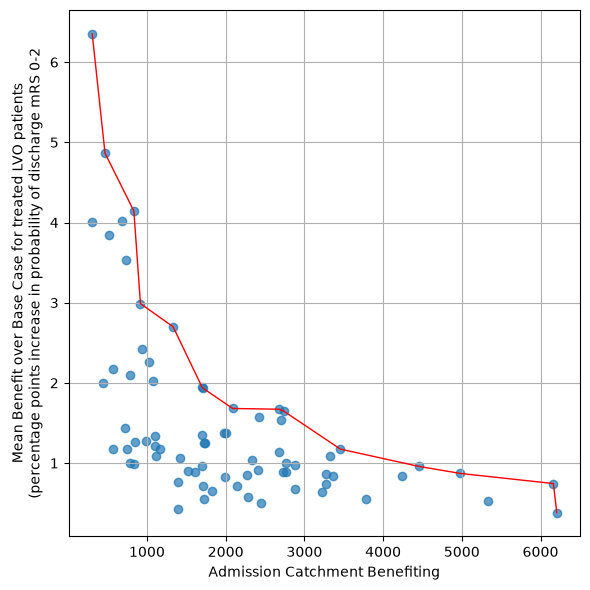

In [10]:
# Plot mean benefit for benefiting admissions against admissions benefiting

fig, ax = plt.subplots(figsize=(6, 6))

x = results_df['Admission Catchment Benefiting']
y = results_df['Mean Benefit for Those Benefitting']

ax.scatter(x, y * 100, alpha=0.7)

# Keep points not dominated by another point in both measures.
is_dominated = results_df.apply(
    lambda row: (
        (x >= row['Admission Catchment Benefiting'])
        & (y >= row['Mean Benefit for Those Benefitting'])
        & (
            (x > row['Admission Catchment Benefiting'])
            | (y > row['Mean Benefit for Those Benefitting'])
        )
    ).any(),
    axis=1
)
pareto_front = results_df.loc[~is_dominated].sort_values(
    'Admission Catchment Benefiting'
)

ax.plot(
    pareto_front['Admission Catchment Benefiting'],
    pareto_front['Mean Benefit for Those Benefitting'] * 100,
    color='red',
    linewidth=1
)

ax.grid()
ax.set_xlabel('Admission Catchment Benefiting')
ax.set_ylabel(
    'Mean Benefit over Base Case for treated LVO patients\n'
    '(percentage points increase in probability of discharge mRS 0-2'
)

plt.tight_layout()
plt.show()